In [2]:
import sys, numpy as np, cv2, torch
print(sys.version)
print(np.__version__, cv2.__version__, torch.__version__)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
2.5.4 5.0.0 2.14.1+cpu


In [3]:
import numpy as np
import cv2 as cv
import zipfile
import io
import requests
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import warnings

from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from PIL import Image

def warn(*args, **kwargs):
    pass

warnings.warn = warn
warnings.filterwarnings('ignore')



In [4]:
def normalize(image):
    """Scale pixel values from 0-255 down to 0-1."""
    return np.array(image) / 255.0

def center_crop(img, output_size):
    """Cut out the centre of an image to the given(height, width)."""
    img = np.array(img)
    start_y = (img.shape[0] - output_size[0]) // 2
    start_x = (img.shape[1] - output_size[1]) // 2
    return img[start_y:start_y + output_size[0], start_x:start_x + output_size[1]]


def shape_process(img, input_size):
    """Pad the image by mirroring its edges until it reaches input_sizes."""
    if img.shape[0] % 2:
        img = cv.resize(img, img.shape[0] // 2, interpolation=cv.INTER_CUBIC)
    padd = int((input_size[0] - img.shape[0]) / 2)
    img = cv.copyMakeBorder(img, padd, padd, padd, padd, cv.BORDER_REFLECT_101)
    return img

In [5]:
zip_file_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/o_kRuP_Bk_Pa2xvo1ly63w/data.zip'

response = requests.get(zip_file_url)
zip_file_bytes = io.BytesIO(response.content)

test_images = []
train_labels = []
train_images = []

with zipfile.ZipFile(zip_file_bytes, 'r') as zip_ref:
    sorted_files = sorted(zip_ref.namelist())
    for file_name in sorted_files:
        if file_name.endswith('.tif'):
            with zip_ref.open(file_name) as file:
                img = Image.open(file).convert('L')  # grayscale
                img = np.array(img)
                if '/train/images/' in file_name:
                    train_images.append(normalize(shape_process(img, (572, 572))))
                elif '/train/labels/' in file_name:
                    cropped_img = center_crop(img, (388, 388))
                    normalized_img = normalize(cropped_img)
                    mask = (normalized_img > 0.5).astype(int)
                    train_labels.append(mask)
                elif '/test/' in file_name:
                    test_images.append(normalize(shape_process(img, (572, 572))))

# Turn the lists into arrays with shape [N, H, W, C]
train_images = np.asarray(train_images, dtype=np.float32)[:, :, :, np.newaxis]
test_images = np.asarray(test_images, dtype=np.float32)[:, :, :, np.newaxis]
train_labels = np.asarray(train_labels, dtype=np.float32)[:, :, :, np.newaxis]

In [6]:
print(f'train_images.shape: {train_images.shape}')
print(f'train_labels.shape: {train_labels.shape}')
print(f'test_images.shape: {test_images.shape}')

train_images.shape: (30, 572, 572, 1)
train_labels.shape: (30, 388, 388, 1)
test_images.shape: (30, 572, 572, 1)


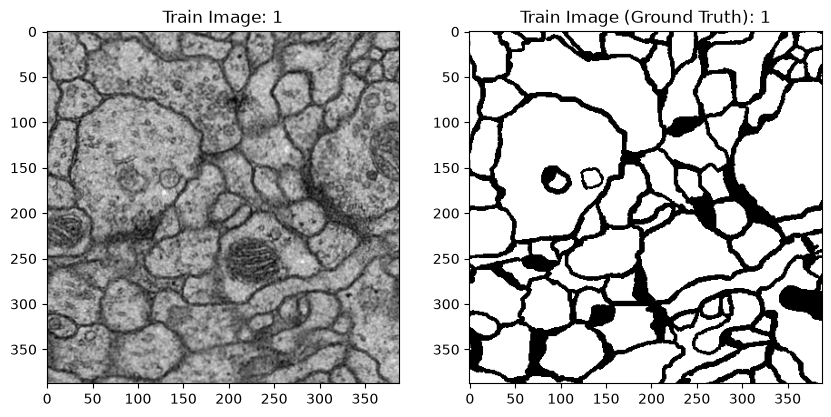

In [7]:
sample_image_index = 1   # try any number from 0 to 29

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.squeeze(center_crop(train_images[sample_image_index], (388, 388))), cmap='gray')
plt.title(f'Train Image: {sample_image_index}')
plt.subplot(1, 2, 2)
plt.imshow(np.squeeze(train_labels[sample_image_index]), cmap='gray')
plt.title(f'Train Image (Ground Truth): {sample_image_index}')
plt.show()

In [8]:
from torch import nn


class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()

        # Downsampling path
        self.conv1 = self.double_conv(1, 64)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = self.double_conv(64, 128)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = self.double_conv(128, 256)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv4 = self.double_conv(256, 512)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv5 = self.double_conv(512, 1024)

        # Upsampling path
        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv6 = self.double_conv(512 + 512, 512)

        self.up_conv1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv6 = self.double_conv(512 + 512, 512)

        self.up_conv2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv7 = self.double_conv(256 + 256, 256)

        self.up_conv3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv8 = self.double_conv(128 + 128, 128)

        self.up_conv4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv9 = self.double_conv(64 + 64, 64)

        self.conv10 = nn.Conv2d(in_channels=64, out_channels=1, kernel_size=1)

    def double_conv(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=0),
            nn.ReLU(inplace=True)
        )

    def center_crop(self, source_tensor, target_shape):
        start_y = (source_tensor.shape[2] - target_shape[2]) // 2
        start_x = (source_tensor.shape[3] - target_shape[3]) // 2
        return source_tensor[:, :, start_y:start_y + target_shape[2], start_x:start_x + target_shape[3]]

    def forward(self, x):
        # Downsampling path
        c1 = self.conv1(x)
        p1 = self.pool1(c1)

        c2 = self.conv2(p1)
        p2 = self.pool2(c2)

        c3 = self.conv3(p2)
        p3 = self.pool3(c3)

        c4 = self.conv4(p3)
        p4 = self.pool4(c4)

        x = self.conv5(p4)

        # Upsampling path with skip connections
        x = self.up_conv1(x)
        x = torch.cat((self.center_crop(c4, x.shape), x), dim=1)
        x = self.conv6(x)

        x = self.up_conv2(x)
        x = torch.cat((self.center_crop(c3, x.shape), x), dim=1)
        x = self.conv7(x)

        x = self.up_conv3(x)
        x = torch.cat((self.center_crop(c2, x.shape), x), dim=1)
        x = self.conv8(x)

        x = self.up_conv4(x)
        x = torch.cat((self.center_crop(c1, x.shape), x), dim=1)
        x = self.conv9(x)

        output = torch.sigmoid(self.conv10(x))
        return output

In [9]:
model = UNet()
print(model)

UNet(
  (conv1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Sequential(
    (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {device} device')

Using cpu device


In [11]:
input_tensor = torch.randn(1, 1, 572, 572)


def print_size(module, input, output):
    print(f"{module.__class__.__name__} output size: {output.size()}")


for layer in model.children():
    layer.register_forward_hook(print_size)

with torch.no_grad():
    output = model(input_tensor)

print("Final output size:", output.size())

Sequential output size: torch.Size([1, 64, 568, 568])
MaxPool2d output size: torch.Size([1, 64, 284, 284])
Sequential output size: torch.Size([1, 128, 280, 280])
MaxPool2d output size: torch.Size([1, 128, 140, 140])
Sequential output size: torch.Size([1, 256, 136, 136])
MaxPool2d output size: torch.Size([1, 256, 68, 68])
Sequential output size: torch.Size([1, 512, 64, 64])
MaxPool2d output size: torch.Size([1, 512, 32, 32])
Sequential output size: torch.Size([1, 1024, 28, 28])
ConvTranspose2d output size: torch.Size([1, 512, 56, 56])
Sequential output size: torch.Size([1, 512, 52, 52])
ConvTranspose2d output size: torch.Size([1, 256, 104, 104])
Sequential output size: torch.Size([1, 256, 100, 100])
ConvTranspose2d output size: torch.Size([1, 128, 200, 200])
Sequential output size: torch.Size([1, 128, 196, 196])
ConvTranspose2d output size: torch.Size([1, 64, 392, 392])
Sequential output size: torch.Size([1, 64, 388, 388])
Conv2d output size: torch.Size([1, 1, 388, 388])
Final output si

In [12]:
from torch.utils.data import DataLoader, TensorDataset, random_split

batch_size = 1

# Use the first 6 images only, to keep this demo fast
train_tensor = torch.from_numpy(train_images[:6]).permute(0, 3, 1, 2).float().to(device)
train_groundtruth_tensor = torch.from_numpy(train_labels[:6]).permute(0, 3, 1, 2).float().to(device)

dataset = TensorDataset(train_tensor, train_groundtruth_tensor)

torch.manual_seed(42)  # makes the random split repeatable

train_size = int(0.8 * len(dataset))   # 4 images for training
val_size = len(dataset) - train_size   # 2 images for validation

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_dl = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [13]:
from tqdm.notebook import tqdm

model = UNet().to(device)
optim = torch.optim.Adam(model.parameters(), lr=0.0001)
epochs = 5

train_losses = []
val_losses = []

for e in tqdm(range(epochs), leave=False, desc="Epoch"):
    # ---- Training ----
    model.train()
    epoch_train_loss = 0

    for data, labels in tqdm(train_dl, leave=False, desc="   Training Dataset"):
        optim.zero_grad()                         # clear old gradients
        prediction = model(data)                  # forward pass
        loss = F.mse_loss(prediction, labels)     # how wrong was it?
        loss.backward()                           # work out how to improve
        optim.step()                              # update the weights
        epoch_train_loss += loss.item()

    average_train_loss = epoch_train_loss / len(train_dl)
    train_losses.append(average_train_loss)

    # ---- Validation ----
    model.eval()
    epoch_val_loss = 0
    with torch.no_grad():
        for data, labels in tqdm(val_dl, leave=False, desc="   Validation Dataset"):
            prediction = model(data)
            loss = F.mse_loss(prediction, labels)
            epoch_val_loss += loss.item()

    average_val_loss = epoch_val_loss / len(val_dl)
    val_losses.append(average_val_loss)

    print(f"Epoch {e+1}, Train Loss: {average_train_loss:.4f}, Val Loss: {average_val_loss:.4f}")

Epoch:   0%|          | 0/5 [00:00<?, ?it/s]

   Training Dataset:   0%|          | 0/4 [00:00<?, ?it/s]

   Validation Dataset:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 1, Train Loss: 0.2435, Val Loss: 0.2398


   Training Dataset:   0%|          | 0/4 [00:00<?, ?it/s]

...

   Validation Dataset:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 4, Train Loss: 0.2281, Val Loss: 0.2210


   Training Dataset:   0%|          | 0/4 [00:00<?, ?it/s]

   Validation Dataset:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 5, Train Loss: 0.2187, Val Loss: 0.2065


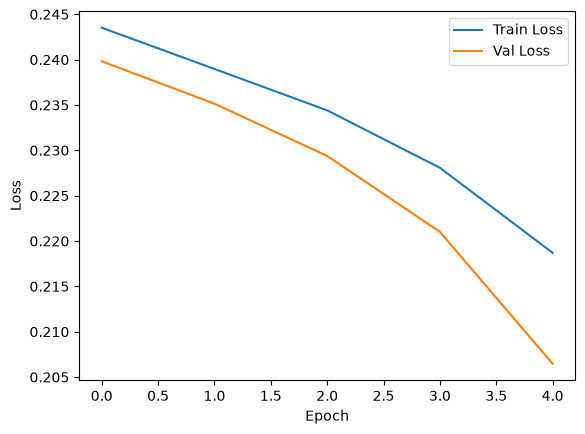

In [14]:
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [15]:
def download_pt_file(url):
    response = requests.get(url)
    return io.BytesIO(response.content)


pt_file_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/Iu482aowoEaP9MgNqhyJ_w/model-epo300.pt'
state_dict = torch.load(download_pt_file(pt_file_url), map_location=torch.device(device))

model = UNet().to(device)
model.load_state_dict(state_dict)
model.eval()

UNet(
  (conv1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Sequential(
    (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d

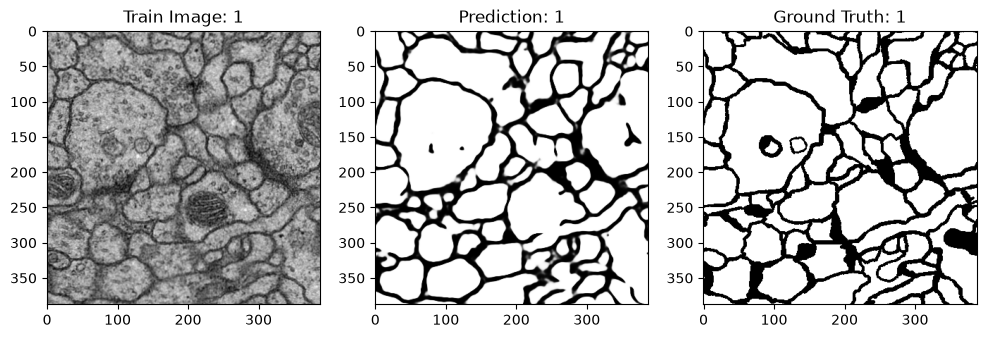

In [16]:
sample_image_index = 1   # try 0 to 29

test_tensor = torch.from_numpy(train_images[sample_image_index]).unsqueeze(0).permute(0, 3, 1, 2).float().to(device)

with torch.no_grad():
    prediction = model(test_tensor)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(np.squeeze(center_crop(train_images[sample_image_index], (388, 388))), cmap='gray')
plt.title(f'Train Image: {sample_image_index}')
plt.subplot(1, 3, 2)
plt.imshow(make_grid(prediction.cpu())[0].numpy(), cmap='gray')
plt.title(f'Prediction: {sample_image_index}')
plt.subplot(1, 3, 3)
plt.imshow(np.squeeze(train_labels[sample_image_index]), cmap='gray')
plt.title(f'Ground Truth: {sample_image_index}')
plt.show()

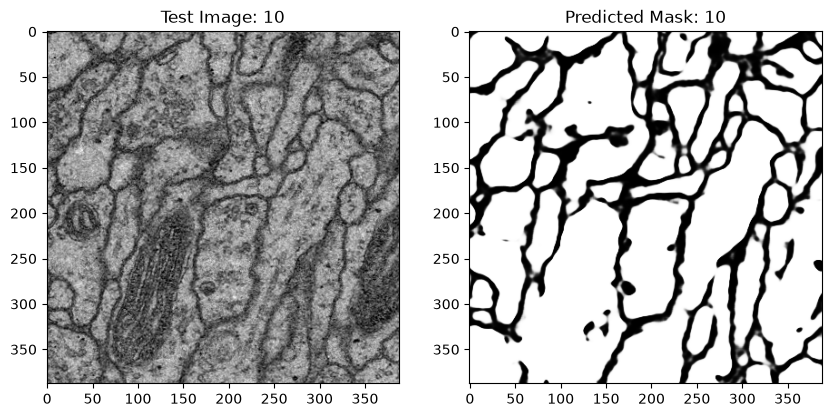

In [17]:
test_image_index = 10   # any number from 0 to 29

test_tensor = torch.from_numpy(test_images[test_image_index]).unsqueeze(0).permute(0, 3, 1, 2).float().to(device)

with torch.no_grad():
    prediction = model(test_tensor)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.squeeze(center_crop(test_images[test_image_index], (388, 388))), cmap='gray')
plt.title(f'Test Image: {test_image_index}')
plt.subplot(1, 2, 2)
plt.imshow(make_grid(prediction.cpu())[0].numpy(), cmap='gray')
plt.title(f'Predicted Mask: {test_image_index}')
plt.show()

In [18]:
import os
os.makedirs("samples/cells", exist_ok=True)

for i in [0, 1, 5, 10, 15]:
    img = np.squeeze(center_crop(train_images[i], (512, 512)))
    Image.fromarray((img * 255).astype(np.uint8)).save(f"samples/cells/cell_{i:02d}.png")
    mask = np.squeeze(train_labels[i])
    Image.fromarray((mask * 255).astype(np.uint8)).save(f"samples/cells/cell_{i:02d}_mask.png")